# 04 · Transfer learning y comparación de modelos

**Objetivo:** comprobar si reutilizar redes preentrenadas mejora o simplifica el reconocimiento de señas frente al baseline (CNN entrenada desde cero en el notebook 03).

**Modelos que se comparan**
| Modelo | Origen | Idea |
|---|---|---|
| Baseline CNN | Propia, desde cero | Referencia (notebook 03) |
| MobileNetV2 | Preentrenada en ImageNet | Ligera y rápida |
| EfficientNetB0 | Preentrenada en ImageNet | Más precisa por parámetro, más lenta |

**Qué es transfer learning:** una red entrenada con millones de imágenes (ImageNet) ya sabe detectar bordes, texturas y formas. Se conserva esa parte (la *base*) y solo se entrena una *cabeza* nueva que decide entre nuestras 29 clases.

**Condiciones iguales para todos:** mismos datos, misma partición 70/15/15 (semilla 42), mismo tamaño de imagen (128×128) y mismo aumento de datos. Así las diferencias se deben al modelo.

## Estrategia: entrenamiento en dos fases

1. **Fase 1 · cabeza (3 épocas):** la base está *congelada* (sus pesos no cambian) y solo se entrena la cabeza con learning rate 1e-3. Evita que una cabeza aleatoria estropee los pesos preentrenados.
2. **Fase 2 · fine-tuning (hasta 12 épocas):** se *descongelan* las últimas capas de la base (30 en MobileNetV2, 40 en EfficientNetB0) y se sigue con un learning rate muy bajo (5e-5) para ajustar esas capas a las señas sin destruir lo aprendido. Las capas BatchNorm siguen congeladas, que es la práctica recomendada. Aquí actúa el *early stopping*.

Los checkpoints y la **reanudación automática** funcionan igual que antes y respetan la fase: si se interrumpe, basta con volver a ejecutar la celda de entrenamiento.

In [1]:
import os, sys, json
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from IPython.display import display
from src.train import train, load_config
from src.compare import latest_run, summary_table, plot_comparison, evaluate_on_photos

cfg = load_config("configs/mobilenetv2.yaml")
RAW = cfg["data"]["raw_dir"]

I0000 00:00:1793058254.774052   22829 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## Configuración de los experimentos
Cada modelo tiene su propio YAML en `configs/`. La celda siguiente los muestra: solo cambian `model.name` y el número de capas a descongelar. La primera vez, Keras descarga los pesos de ImageNet (unos pocos MB, requiere internet).

In [2]:
for f in ("mobilenetv2", "efficientnetb0"):
    print(f"--- configs/{f}.yaml ---")
    print(Path(f"configs/{f}.yaml").read_text())

--- configs/mobilenetv2.yaml ---
# Transfer learning: MobileNetV2 preentrenada en ImageNet, en dos fases.
data:
  raw_dir: data/raw/asl_alphabet_train/asl_alphabet_train
  split: {train: 0.70, val: 0.15, test: 0.15}
  seed: 42
  img_size: [128, 128]
  batch_size: 64

model:
  name: mobilenetv2
  weights: imagenet
  dropout: 0.3

train:
  epochs_head: 3               # fase 1: base congelada, solo la cabeza
  epochs_finetune: 12          # fase 2: se descongelan las últimas capas (máximo)
  lr_head: 0.001
  lr_finetune: 0.00005
  unfreeze_layers: 30
  mixed_precision: true
  monitor: val_accuracy
  early_stopping_patience: 4   # solo en la fase 2
  reduce_lr_patience: 2

--- configs/efficientnetb0.yaml ---
# Transfer learning: EfficientNetB0 preentrenada en ImageNet, en dos fases.
data:
  raw_dir: data/raw/asl_alphabet_train/asl_alphabet_train
  split: {train: 0.70, val: 0.15, test: 0.15}
  seed: 42
  img_size: [128, 128]
  batch_size: 64

model:
  name: efficientnetb0
  weights: imagen

## Entrenamiento: MobileNetV2
Ejecuta la celda y espera. Verás primero la fase 1 y luego la fase 2 (el mensaje `--- Fase ...` lo indica). Al terminar se guardan en `experiments/<fecha>_mobilenetv2/` el mejor modelo, el historial, las curvas y la evaluación en test.

In [3]:
run_mobilenet = train("configs/mobilenetv2.yaml", name="mobilenetv2")

GPUs detectadas: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


I0000 00:00:1793054119.762781    6305 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5560 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060, pci bus id: 0000:10:00.0, compute capability: 8.9


Corrida: experiments/20261026-1735_mobilenetv2 (nueva) | modelo: mobilenetv2
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
--- Fase 1: cabeza (base congelada), épocas 1-3
Epoch 1/3


I0000 00:00:1793054126.697098    6814 cuda_dnn.cc:461] Loaded cuDNN version 92700


952/952 - 64s - 67ms/step - accuracy: 0.7243 - loss: 0.9428 - val_accuracy: 0.9011 - val_loss: 0.3300 - learning_rate: 0.0010
Epoch 2/3
952/952 - 56s - 58ms/step - accuracy: 0.8569 - loss: 0.4597 - val_accuracy: 0.9283 - val_loss: 0.2316 - learning_rate: 0.0010
Epoch 3/3
952/952 - 57s - 59ms/step - accuracy: 0.8741 - loss: 0.3925 - val_accuracy: 0.9417 - val_loss: 0.1902 - learning_rate: 0.0010
--- Fase 2: fine-tuning de las últimas 30 capas, épocas 4-15
Epoch 4/15
952/952 - 75s - 79ms/step - accuracy: 0.9386 - loss: 0.1867 - val_accuracy: 0.9648 - val_loss: 0.1072 - learning_rate: 5.0000e-05
Epoch 5/15
952/952 - 66s - 69ms/step - accuracy: 0.9711 - loss: 0.0846 - val_accuracy: 0.9848 - val_loss: 0.0480 - learning_rate: 5.0000e-05
Epoch 6/15
952/952 - 67s - 70ms/step - accuracy: 0.9805 - loss: 0.0577 - val_accuracy: 0.9808 - val_loss: 0.0576 - learning_rate: 5.0000e-05
Epoch 7/15
952/952 - 67s - 70ms/step - accuracy: 0.9852 - loss: 0.0426 - val_accuracy: 0.9918 - val_loss: 0.0234 - lea

## Entrenamiento: EfficientNetB0
Mismo procedimiento. Es una red más profunda, así que cada época puede tardar bastante más que en MobileNetV2.

In [4]:
run_efficientnet = train("configs/efficientnetb0.yaml", name="efficientnetb0")

GPUs detectadas: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Corrida: experiments/20261026-1751_efficientnetb0 (nueva) | modelo: efficientnetb0
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
--- Fase 1: cabeza (base congelada), épocas 1-3
Epoch 1/3
952/952 - 82s - 86ms/step - accuracy: 0.7313 - loss: 1.0986 - val_accuracy: 0.8968 - val_loss: 0.4173 - learning_rate: 0.0010
Epoch 2/3
952/952 - 72s - 76ms/step - accuracy: 0.8622 - loss: 0.5257 - val_accuracy: 0.9193 - val_loss: 0.2939 - learning_rate: 0.0010
Epoch 3/3
952/952 - 74s - 78ms/step - accuracy: 0.8834 - loss: 0.4204 - val_accuracy: 0.9333 - val_loss: 0.2354 - learning_rate: 0.0010
--- Fase 2: fine-tuning de las últimas 40 capas, épocas 4-15
Epoch 4/15
952/952 - 117s - 123ms/step - accuracy: 0.9491 - loss: 0.1581 - val_accuracy: 0.9770 - val_loss: 0.0701 - learning_rate: 5.0000e-05
Epoch 5/15
952/952 - 102s - 107ms/step - accuracy: 0.9764 - loss: 0.0728 - val_accuracy: 0.9893 - val_loss: 0.0369 - learn

## Comparación en el conjunto de test
Se toma la última corrida terminada de cada modelo (el baseline sale del notebook 03). La tabla resume parámetros, épocas, mejores métricas y tiempo por época.

> **Cómo interpretarla:** con este dataset el test es muy fácil (fotos casi idénticas entre sí), así que es probable que todos los modelos superen el 99 %. Por eso las diferencias pequeñas aquí **no son concluyentes**; la prueba más informativa es la de *fotos propias* más abajo. El tiempo por época de corridas antiguas puede no estar disponible (aparece vacío).

In [2]:
runs = {
    "Baseline": latest_run("baseline"),
    "MobileNetV2": latest_run("mobilenetv2"),
    "EfficientNetB0": latest_run("efficientnetb0"),
}
summary_table(runs)

I0000 00:00:1793058287.127919   22829 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5560 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060, pci bus id: 0000:10:00.0, compute capability: 8.9
/home/juan/proyectos/asl-sign-language-recognition/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 58 variables whereas the saved optimizer has 62 variables. 
  saveable.load_own_variables(store)


,corrida,parámetros (M),épocas,mejor val_accuracy,mínimo val_loss,test accuracy,s/época (mediana)
Baseline,20261024-1217_baseline,1.21,25,0.9999,0.0002,1.0000,NaN
MobileNetV2,20261026-1735_mobilenetv2,2.30,15,0.9973,0.0068,0.9977,66.1
EfficientNetB0,20261026-1751_efficientnetb0,4.09,15,0.9983,0.0050,0.9977,98.8


### Curvas de todos los modelos

=== Baseline (20261024-1217_baseline) ===
Accuracy en test: 1.0000


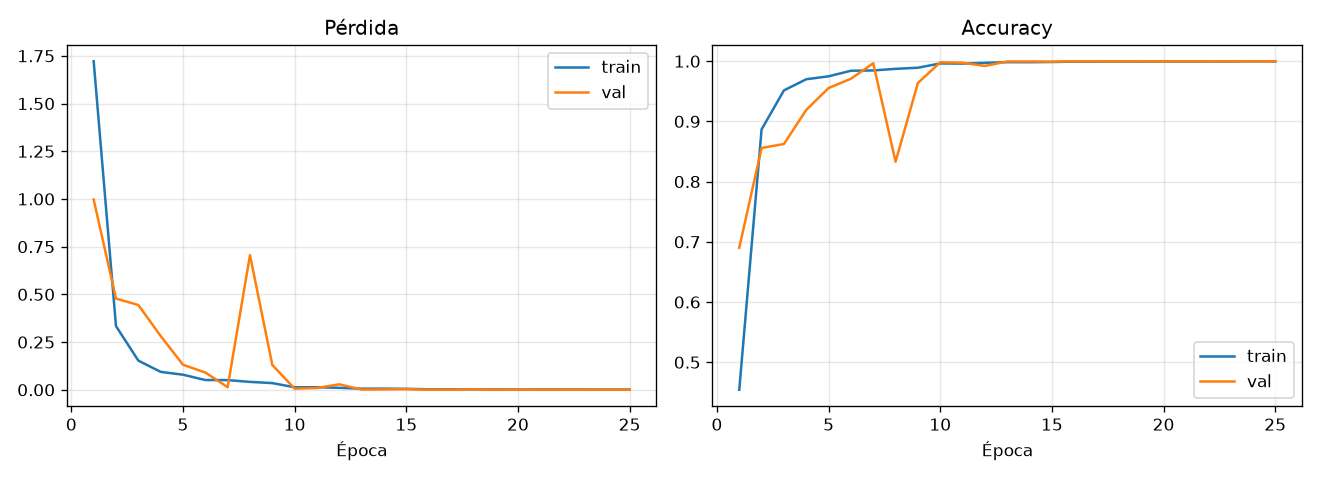

=== MobileNetV2 (20261026-1735_mobilenetv2) ===
Accuracy en test: 0.9977


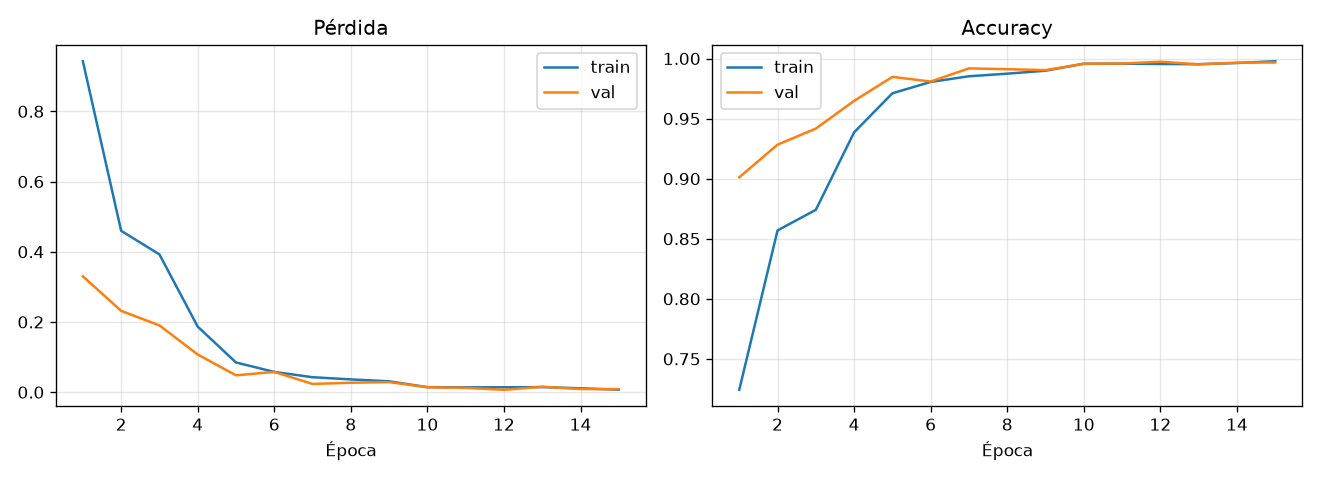

=== EfficientNetB0 (20261026-1751_efficientnetb0) ===
Accuracy en test: 0.9977


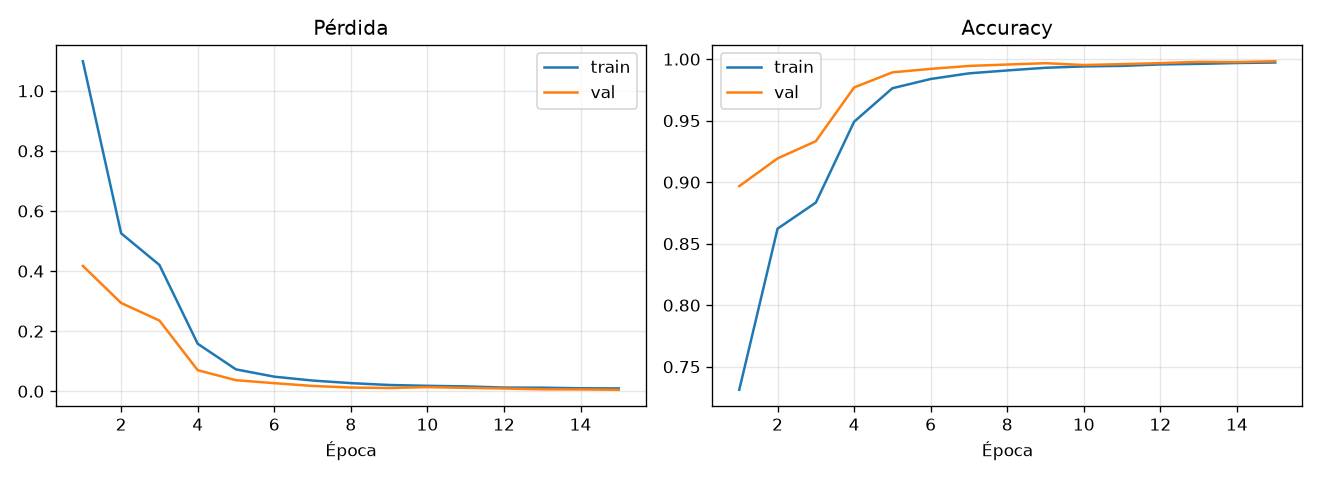

In [10]:
from IPython.display import Image, display
import json

for modelo, run_dir in runs.items():
    print(f"=== {modelo} ({run_dir.name}) ===")
    metrics = json.loads((run_dir / "metrics.json").read_text())
    print(f"Accuracy en test: {metrics['accuracy']:.4f}")
    display(Image(filename=str(run_dir / "curves.png")))
    #display(Image(filename=str(run_dir / "confusion_matrix.png")))  # Descomentar si se quiere ver la matriz de confusión

### ¿En qué época se obtuvo el mejor valor de accuracy?

In [11]:
import pandas as pd

for modelo, rd in runs.items():
    h = pd.read_csv(rd / "history.csv")
    mejor = int(h.loc[h.val_accuracy.idxmax(), "epoch"])
    print(f"{modelo}: {len(h)} épocas | mejor val_accuracy en la época {mejor}")

Baseline: 25 épocas | mejor val_accuracy en la época 19
MobileNetV2: 15 épocas | mejor val_accuracy en la época 12
EfficientNetB0: 15 épocas | mejor val_accuracy en la época 15


## Curvas de validación
Accuracy y pérdida de validación por época. Las líneas punteadas marcan dónde empieza el fine-tuning en cada modelo de transfer learning. Fíjate en cuántas épocas tarda cada uno en estabilizarse y si el fine-tuning mejora la curva.

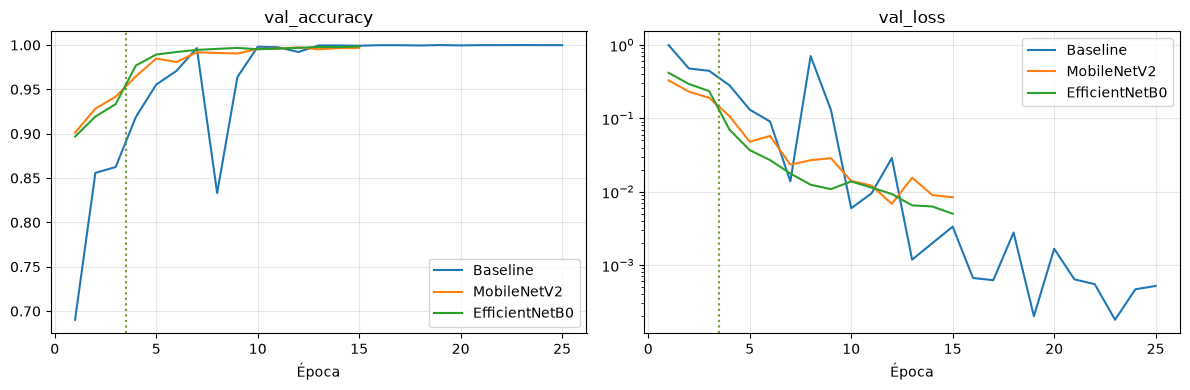

In [3]:
plot_comparison(runs)

## Prueba con fotos propias
Es la comparación que mide **generalización real**: fotos tuyas, con tu fondo, tu luz y tu mano, que ningún modelo vio durante el entrenamiento. Se esperan las fotos en `data/mis_fotos/<clase>/` (la misma organización del notebook 03). Si la carpeta no existe, la celda lo indica y se puede saltar.

In [4]:
from src.visualize import list_own_photos

try:
    photos = list_own_photos("data/mis_fotos", json.loads((runs["Baseline"] / "final" / "classes.json").read_text()))
except FileNotFoundError as e:
    photos = None
    print(e)

if photos is not None:
    tabla_fotos, detalle = evaluate_on_photos(runs, photos)
    display(tabla_fotos)

/home/juan/proyectos/asl-sign-language-recognition/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 58 variables whereas the saved optimizer has 62 variables. 
  saveable.load_own_variables(store)
I0000 00:00:1793058292.428384   23083 cuda_dnn.cc:461] Loaded cuDNN version 92700
/home/juan/proyectos/asl-sign-language-recognition/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_1', because it has 26 variables whereas the saved optimizer has 30 variables. 
  saveable.load_own_variables(store)
/home/juan/proyectos/asl-sign-language-recognition/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_3', because it has 46 variables whereas the saved optimizer has 50 variables. 
  saveable.load_own_variables(store)


,fotos,aciertos,accuracy fotos propias
Baseline,6,3,0.5000
MobileNetV2,6,4,0.6667
EfficientNetB0,6,5,0.8333


### Errores por modelo
Lista de las fotos mal clasificadas por cada modelo: la clase real, la predicha y la confianza. Sirve para ver si todos fallan en las mismas señas (letras parecidas como M/N o U/V) o si el error es de un modelo concreto.

In [5]:
if photos is not None:
    for modelo, res in detalle.items():
        err = res[~res.correct]
        print(f"{modelo}: {len(err)} errores de {len(res)} fotos")
        if len(err):
            display(err[["path", "label", "pred", "conf"]].round(3))

Baseline: 3 errores de 6 fotos


,path,label,pred,conf
0,data/mis_fotos/B/B_99.jpg,B,W,0.456
4,data/mis_fotos/V/V_98.jpg,V,B,0.895
5,data/mis_fotos/V/V_99.jpg,V,O,0.497


MobileNetV2: 2 errores de 6 fotos


,path,label,pred,conf
0,data/mis_fotos/B/B_99.jpg,B,E,0.467
2,data/mis_fotos/L/L_99.jpg,L,V,0.995


EfficientNetB0: 1 errores de 6 fotos


,path,label,pred,conf
2,data/mis_fotos/L/L_99.jpg,L,Y,0.559


### Ver la cuadrícula de un modelo concreto

Se cambia la clave de runs para elegir el modelo.

/home/juan/proyectos/asl-sign-language-recognition/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_3', because it has 46 variables whereas the saved optimizer has 50 variables. 
  saveable.load_own_variables(store)


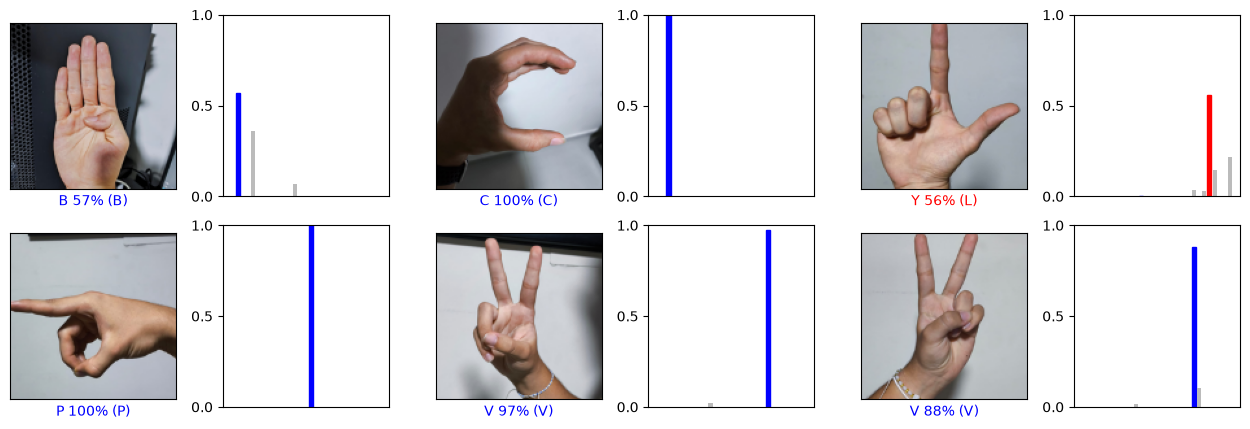

In [7]:
from tensorflow import keras
from src.visualize import predict_own_photos, plot_grid

rd = runs["EfficientNetB0"]   # "MobileNetV2" / "EfficientNetB0" / "Baseline"
model = keras.models.load_model(rd / "final" / "model.keras")
class_names = json.loads((rd / "final" / "classes.json").read_text())
img_size = tuple(load_config(rd / "config.yaml")["data"]["img_size"])

res, images, probs = predict_own_photos(model, photos, class_names, img_size)
inicio, n = 0, 15   # cambia 'inicio' para paginar
sel = slice(inicio, inicio + n)
plot_grid(images[sel], probs[sel], class_names, res.true_id.to_numpy()[sel], n_cols=3)

## Conclusiones
*Completa esta sección con tus resultados:*

- **Mejor modelo en test:** …
- **Mejor modelo en fotos propias:** …
- **Velocidad (s/época) y tamaño (M parámetros):** …
- **¿Mejoró el transfer learning frente al baseline?** …
- **Señas que más se confunden:** …
- **Siguiente paso:** por ejemplo, más aumento de datos (brillo, fondos), una partición por bloques para un test más exigente, o más fotos propias.

## Conclusiones

### Convergencia y presupuesto de épocas
| Modelo | Épocas entrenadas | Mejor `val_accuracy` en la época | Motivo de parada |
|---|---|---|---|
| Baseline | 25 (máximo 30) | 19 | Early stopping (paciencia 6) |
| MobileNetV2 | 15 (3 de cabeza + 12 de fine-tuning) | 12 | Llegó al tope de épocas |
| EfficientNetB0 | 15 (3 de cabeza + 12 de fine-tuning) | 15 | Llegó al tope de épocas |

- **Baseline:** convergió. Su mejor época fue la 19 y el early stopping cortó en la 25.
- **MobileNetV2:** convergió. Su mejor época fue la 12 y las tres siguientes no mejoraron, así que más épocas casi seguro no cambiarían el resultado.
- **EfficientNetB0:** **no convergió del todo.** Su mejor época fue la última. Entre las épocas 10 y 15 la `val_loss` bajó de 0,0138 a 0,0050 y la `val_accuracy` subió de 0,9952 a 0,9983, ambas aún en descenso. El margen restante es pequeño, de como máximo medio punto de accuracy de validación.
- **Decisión:** por ahora no se reentrena ninguno. En MobileNetV2 no aportaría nada. En EfficientNetB0 podría aportar algo, pero se decide tras la prueba con fotos propias.
- **Equidad de la comparación:** los modelos no tuvieron el mismo presupuesto de épocas (el baseline tuvo hasta 30 y los preentrenados 15). El early stopping decide cuándo para cada uno, pero EfficientNetB0 quedó limitado por el tope y no por su propia convergencia. Tenerlo presente al comparar.

### Resultados en test
- **Baseline:** test accuracy de 1,0000, con matriz de confusión diagonal perfecta.
- **MobileNetV2 y EfficientNetB0:** *(completar con la tabla de resumen)*.
- **Limitación:** el dataset tiene fotos casi idénticas entre sí y la partición es aleatoria, así que el test es muy fácil y las diferencias entre modelos aquí **no son concluyentes**.

### Fotos propias
*(Pendiente: la prueba aún no está completa porque faltan fotos por tomar.)*
- Accuracy de cada modelo con fotos propias: …
- Señas que más se confunden: …
- Si EfficientNetB0 acierta todas las fotos, no hace falta reentrenarlo. Si falla alguna, reentrenar con `epochs_finetune: 25` para comprobar si más épocas ayudan.

### Próximos pasos
- Completar las fotos propias, con variedad de fondo, luz y distancia (y otra persona, si es posible).
- Valorar una partición por bloques para un test más exigente.
- Si los modelos fallan con las fotos propias: más aumento de datos (brillo, contraste, fondos) o descongelar más capas (`unfreeze_layers`).